# Veritas Bureau — Notebook 2: Evaluation & Analysis
**IE University · Gen AI & Agents Course · April 2026**

Quantitative evaluation of the multi-agent pipeline on 100 articles (50 REAL + 50 FAKE).

---

In [547]:
import sys, os
if not os.path.exists('config.py'):
    os.chdir('..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_curve, auc
)

plt.style.use('dark_background')
COLORS = {'FAKE': '#f87171', 'REAL': '#4ade80', 'neutral': '#6B6660', 'accent': '#C8C3B8'}
print("Libraries loaded")

Libraries loaded


## 1. Load Results

In [548]:
RESULTS_PATH = "results/results.csv"

df = pd.read_csv(RESULTS_PATH)
print(f"Loaded {len(df)} results")
print(f"Columns: {list(df.columns)}")
df.head()

Loaded 100 results
Columns: ['title', 'true_label', 'predicted_label', 'confidence', 'hf_label', 'hf_confidence', 'bias_score', 'credibility_score', 'tone', 'n_claims', 'n_contradicted', 'n_supported', 'devils_advocate_triggered', 'da_recommendation', 'processing_time', 'judge_summary', 'subject', 'date']


,title,true_label,predicted_label,confidence,hf_label,hf_confidence,bias_score,credibility_score,tone,n_claims,n_contradicted,n_supported,devils_advocate_triggered,da_recommendation,processing_time,judge_summary,subject,date
0,"Kenya's repeat presidential poll was free, fai...",REAL,REAL,0.95,REAL,0.9999,0.25,0.75,neutral,3,0,3,False,NaN,133.84,The article's claims are supported by evidence...,worldnews,"October 30, 2017"
1,Poland wants strong euro zone before mulling m...,REAL,REAL,0.92,REAL,0.9999,0.23,0.75,neutral,3,0,2,False,NaN,167.70,The article's claims about Poland's stance on ...,worldnews,"October 29, 2017"
2,Senate confirms Trump pick Perry as energy sec...,REAL,REAL,0.95,REAL,0.9999,0.23,0.75,informative,3,0,3,False,NaN,169.46,All claims were supported by evidence. The art...,politicsNews,"March 2, 2017"
3,HOW LEFT- LEANING GOOGLE’S SECRET DECISIONS CO...,FAKE,FAKE,0.80,FAKE,0.9997,0.85,0.25,inflammatory,7,0,4,True,UPHOLD,224.17,The article contains several unsupported asser...,left-news,"Aug 23, 2015"
4,REPORT: Team Trump Just Hired A Crackpot Anti...,FAKE,FAKE,0.92,FAKE,0.9998,0.85,0.25,inflammatory,5,0,4,False,NaN,137.65,The article contains several supported claims ...,News,"November 16, 2016"


In [549]:
# Filter to labeled rows and standardize
df = df[df["true_label"].isin(["REAL", "FAKE"])].copy()
df["correct"] = df["true_label"] == df["predicted_label"]
df["true_binary"] = (df["true_label"] == "REAL").astype(int)
df["pred_binary"] = (df["predicted_label"] == "REAL").astype(int)

print(f"Labeled articles: {len(df)}")
print(f"True label distribution:\n{df['true_label'].value_counts()}")
print(f"Predicted label distribution:\n{df['predicted_label'].value_counts()}")

Labeled articles: 100
True label distribution:
REAL    50
FAKE    50
Name: true_label, dtype: int64
Predicted label distribution:
FAKE    54
REAL    46
Name: predicted_label, dtype: int64


## 2. Core Metrics

In [550]:
acc = accuracy_score(df["true_label"], df["predicted_label"])
prec = precision_score(df["true_binary"], df["pred_binary"], zero_division=0)
rec = recall_score(df["true_binary"], df["pred_binary"], zero_division=0)
f1 = f1_score(df["true_binary"], df["pred_binary"], zero_division=0)

print(f"{'Metric':<20} {'Value':>10}")
print("-" * 32)
print(f"{'Accuracy':<20} {acc:>10.1%}")
print(f"{'Precision (REAL)':<20} {prec:>10.1%}")
print(f"{'Recall (REAL)':<20} {rec:>10.1%}")
print(f"{'F1 (REAL)':<20} {f1:>10.1%}")
print()
print(classification_report(df["true_label"], df["predicted_label"]))

Metric                    Value
--------------------------------
Accuracy                  94.0%
Precision (REAL)          97.8%
Recall (REAL)             90.0%
F1 (REAL)                 93.8%

              precision    recall  f1-score   support

        FAKE       0.91      0.98      0.94        50
        REAL       0.98      0.90      0.94        50

    accuracy                           0.94       100
   macro avg       0.94      0.94      0.94       100
weighted avg       0.94      0.94      0.94       100



## 3. Confusion Matrix

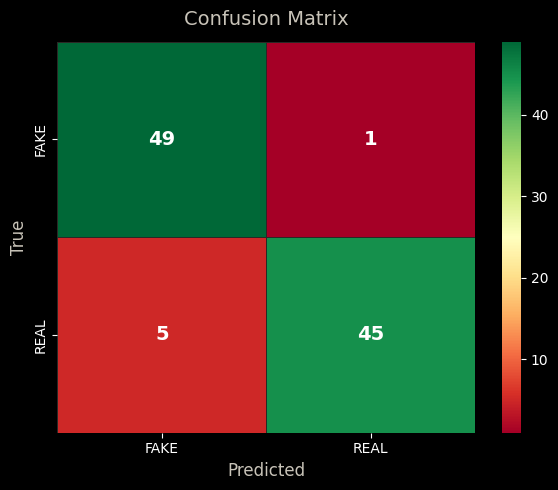

Saved to results/confusion_matrix.png


In [551]:
labels = ["FAKE", "REAL"]
cm = confusion_matrix(df["true_label"], df["predicted_label"], labels=labels)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="RdYlGn",
    xticklabels=labels, yticklabels=labels,
    ax=ax, linewidths=0.5, linecolor='#2a2825',
    annot_kws={"size": 14, "weight": "bold"}
)
ax.set_xlabel("Predicted", fontsize=12, color=COLORS["accent"])
ax.set_ylabel("True", fontsize=12, color=COLORS["accent"])
ax.set_title("Confusion Matrix", fontsize=14, color=COLORS["accent"], pad=12)
plt.tight_layout()
plt.savefig("results/confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved to results/confusion_matrix.png")

## 4. Confidence Distribution

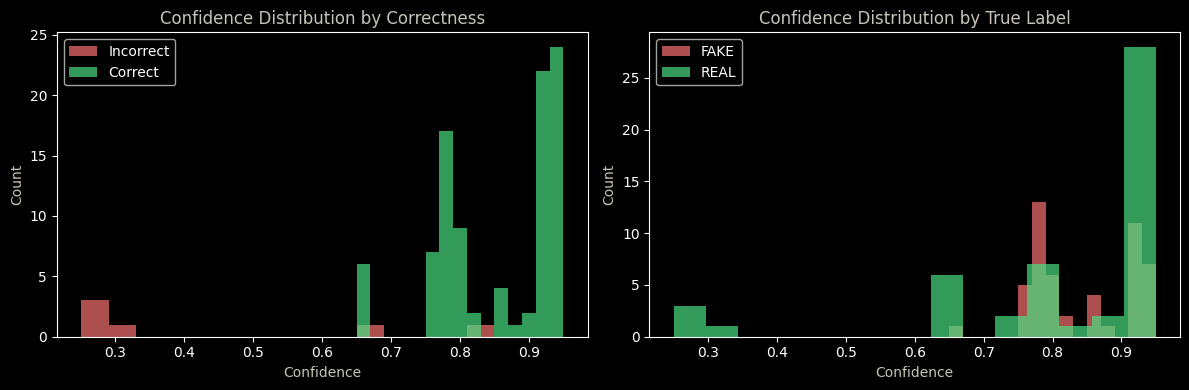

In [552]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Confidence by correctness
ax = axes[0]
for correct, grp in df.groupby("correct"):
    label = "Correct" if correct else "Incorrect"
    color = COLORS["REAL"] if correct else COLORS["FAKE"]
    ax.hist(grp["confidence"], bins=15, alpha=0.7, label=label, color=color)
ax.set_title("Confidence Distribution by Correctness", color=COLORS["accent"])
ax.set_xlabel("Confidence", color=COLORS["accent"])
ax.set_ylabel("Count", color=COLORS["accent"])
ax.legend()

# Confidence by true label
ax = axes[1]
for label, grp in df.groupby("true_label"):
    ax.hist(grp["confidence"], bins=15, alpha=0.7, label=label, color=COLORS.get(label, "gray"))
ax.set_title("Confidence Distribution by True Label", color=COLORS["accent"])
ax.set_xlabel("Confidence", color=COLORS["accent"])
ax.set_ylabel("Count", color=COLORS["accent"])
ax.legend()

plt.tight_layout()
plt.savefig("results/confidence_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Agent Signal Analysis

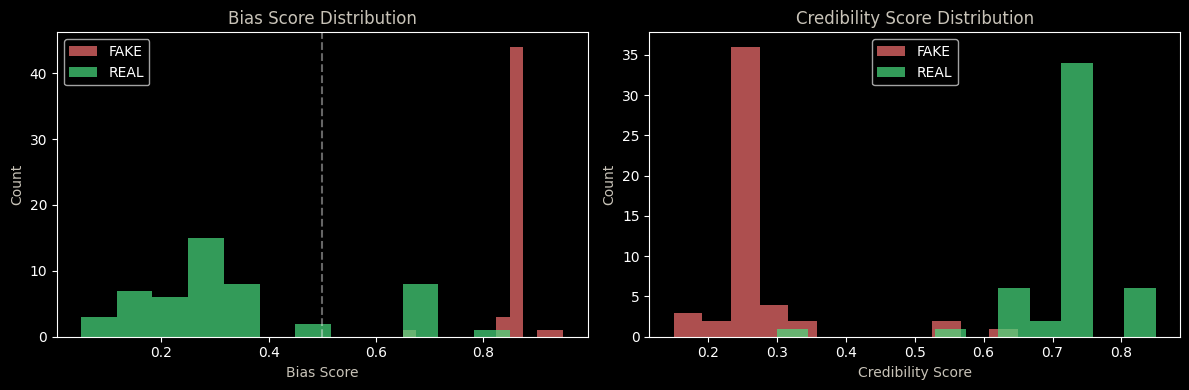

In [553]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Bias score by true label
ax = axes[0]
for label, grp in df.groupby("true_label"):
    if "bias_score" in grp.columns:
        ax.hist(grp["bias_score"].dropna(), bins=12, alpha=0.7, label=label, color=COLORS.get(label, "gray"))
ax.set_title("Bias Score Distribution", color=COLORS["accent"])
ax.set_xlabel("Bias Score", color=COLORS["accent"])
ax.set_ylabel("Count", color=COLORS["accent"])
ax.legend()
ax.axvline(0.5, color='white', linestyle='--', alpha=0.4, label='Threshold 0.5')

# Credibility score by true label
ax = axes[1]
for label, grp in df.groupby("true_label"):
    if "credibility_score" in grp.columns:
        ax.hist(grp["credibility_score"].dropna(), bins=12, alpha=0.7, label=label, color=COLORS.get(label, "gray"))
ax.set_title("Credibility Score Distribution", color=COLORS["accent"])
ax.set_xlabel("Credibility Score", color=COLORS["accent"])
ax.set_ylabel("Count", color=COLORS["accent"])
ax.legend()

plt.tight_layout()
plt.savefig("results/signal_analysis.png", dpi=150, bbox_inches="tight")
plt.show()

In [554]:
# Mean signal values by true label
signal_cols = [c for c in ["bias_score", "credibility_score", "n_claims", "n_contradicted", "n_supported"] if c in df.columns]
print("Mean agent signals by true label:")
print(df.groupby("true_label")[signal_cols].mean().round(3))

Mean agent signals by true label:
            bias_score  credibility_score  n_claims  n_contradicted  \
true_label                                                            
FAKE             0.848              0.270      3.98            0.24   
REAL             0.323              0.735      3.74            0.20   

            n_supported  
true_label               
FAKE               2.70  
REAL               2.84  


## 6. Accuracy by Subject

Accuracy by subject:
        subject  accuracy    n  n_fake  n_real
Government News  1.000000  3.0     3.0     0.0
    Middle-east  1.000000  2.0     2.0     0.0
           News  0.954545 22.0    22.0     0.0
      left-news  1.000000 12.0    12.0     0.0
       politics  1.000000 11.0    11.0     0.0
   politicsNews  0.962963 27.0     0.0    27.0
      worldnews  0.826087 23.0     0.0    23.0


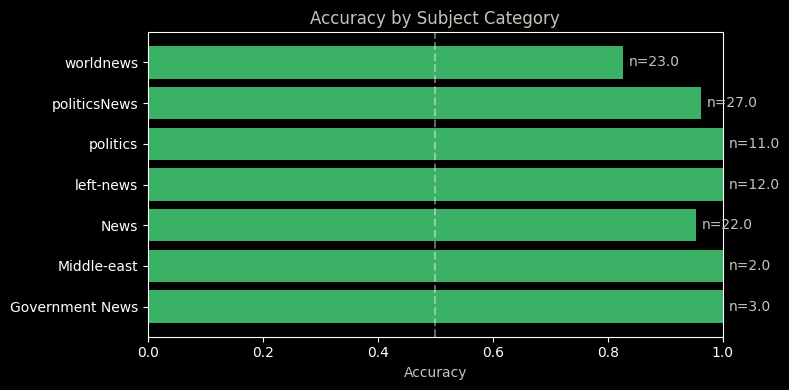

In [555]:
if "subject" in df.columns and df["subject"].notna().any():
    subj_acc = df.groupby("subject").apply(
        lambda g: pd.Series({
            "accuracy": (g["true_label"] == g["predicted_label"]).mean(),
            "n": len(g),
            "n_fake": (g["true_label"] == "FAKE").sum(),
            "n_real": (g["true_label"] == "REAL").sum(),
        })
    ).reset_index()
    print("Accuracy by subject:")
    print(subj_acc.to_string(index=False))

    fig, ax = plt.subplots(figsize=(8, 4))
    colors = [COLORS["REAL"] if a >= 0.7 else COLORS["FAKE"] for a in subj_acc["accuracy"]]
    bars = ax.barh(subj_acc["subject"], subj_acc["accuracy"], color=colors, alpha=0.8)
    ax.set_xlim(0, 1)
    ax.axvline(0.5, color='white', linestyle='--', alpha=0.4)
    ax.set_xlabel("Accuracy", color=COLORS["accent"])
    ax.set_title("Accuracy by Subject Category", color=COLORS["accent"])
    for bar, n in zip(bars, subj_acc["n"]):
        ax.text(bar.get_width() + 0.01, bar.get_y() + bar.get_height()/2,
                f"n={n}", va="center", fontsize=10, color=COLORS["accent"])
    plt.tight_layout()
    plt.savefig("results/accuracy_by_subject.png", dpi=150, bbox_inches="tight")
    plt.show()
else:
    print("No 'subject' column found in results — skipping subject analysis.")

## 7. Accuracy by Time Period

Accuracy by year:
 year  accuracy    n
 2015  1.000000  4.0
 2016  1.000000 28.0
 2017  0.911765 68.0


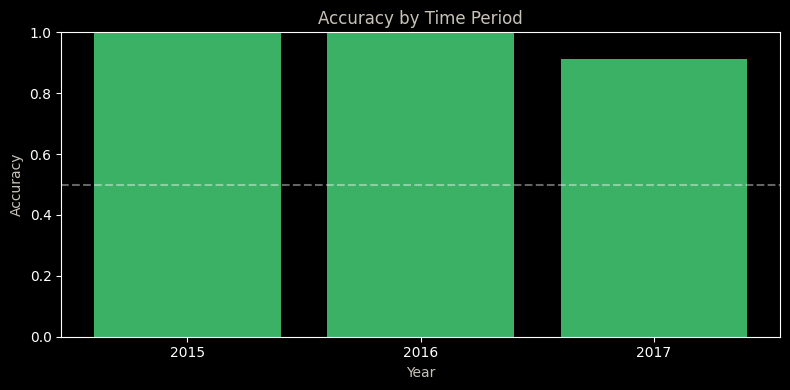

In [556]:
if "date" in df.columns and df["date"].notna().any():
    df["date_parsed"] = pd.to_datetime(df["date"], errors="coerce")
    df["year_month"] = df["date_parsed"].dt.to_period("M").astype(str)
    df["year"] = df["date_parsed"].dt.year

    time_acc = df.groupby("year").apply(
        lambda g: pd.Series({
            "accuracy": (g["true_label"] == g["predicted_label"]).mean(),
            "n": len(g),
        })
    ).reset_index().dropna()
    time_acc = time_acc[time_acc["n"] >= 2]  # skip years with too few samples

    print("Accuracy by year:")
    print(time_acc.to_string(index=False))

    if len(time_acc) > 0:
        fig, ax = plt.subplots(figsize=(8, 4))
        ax.bar(time_acc["year"].astype(str), time_acc["accuracy"],
               color=COLORS["REAL"], alpha=0.8)
        ax.set_ylim(0, 1)
        ax.axhline(0.5, color='white', linestyle='--', alpha=0.4)
        ax.set_xlabel("Year", color=COLORS["accent"])
        ax.set_ylabel("Accuracy", color=COLORS["accent"])
        ax.set_title("Accuracy by Time Period", color=COLORS["accent"])
        plt.tight_layout()
        plt.savefig("results/accuracy_by_time.png", dpi=150, bbox_inches="tight")
        plt.show()
else:
    print("No 'date' column found in results — skipping time period analysis.")

## 8. Devil's Advocate Impact

In [557]:
if "devils_advocate_triggered" in df.columns:
    da_df = df[df["devils_advocate_triggered"] == True].copy()
    non_da_df = df[df["devils_advocate_triggered"] == False].copy()

    print(f"Articles where Devil's Advocate triggered: {len(da_df)} / {len(df)} ({len(da_df)/len(df):.1%})")

    if len(da_df) > 0:
        da_acc = (da_df["true_label"] == da_df["predicted_label"]).mean()
        non_da_acc = (non_da_df["true_label"] == non_da_df["predicted_label"]).mean() if len(non_da_df) > 0 else float('nan')
        print(f"Accuracy WITH Devil's Advocate: {da_acc:.1%}")
        print(f"Accuracy WITHOUT Devil's Advocate: {non_da_acc:.1%}")

        if "da_recommendation" in da_df.columns:
            print(f"\nDA recommendations:\n{da_df['da_recommendation'].value_counts()}")

Articles where Devil's Advocate triggered: 52 / 100 (52.0%)
Accuracy WITH Devil's Advocate: 88.5%
Accuracy WITHOUT Devil's Advocate: 100.0%

DA recommendations:
UPHOLD      48
OVERTURN     4
Name: da_recommendation, dtype: int64


## 9. Error Analysis

In [558]:
errors = df[~df["correct"]].copy()
print(f"Total errors: {len(errors)} / {len(df)} ({len(errors)/len(df):.1%})")
print()

# Show up to 8 misclassified articles
display_cols = ["title", "true_label", "predicted_label", "confidence", "bias_score", "credibility_score"]
display_cols = [c for c in display_cols if c in errors.columns]

for _, row in errors.head(8).iterrows():
    print(f"Title: {str(row.get('title',''))[:70]}")
    print(f"  True: {row.get('true_label')}  →  Predicted: {row.get('predicted_label')}  (conf: {row.get('confidence', 0):.0%})")
    if "judge_summary" in row:
        print(f"  Judge: {str(row.get('judge_summary',''))[:100]}")
    print()

Total errors: 6 / 100 (6.0%)

Title: Suicide bomber kills 13 others in northeast Nigerian city: police offi
  True: REAL  →  Predicted: FAKE  (conf: 25%)
  Judge: One claim was contradicted by fact-checking evidence, but the article's overall credibility and tone

Title:  Read Former FBI Director James Comey’s Full Prepared Testimony Ahead 
  True: FAKE  →  Predicted: REAL  (conf: 65%)
  Judge: The article contains mostly supported claims and a moderate bias score. The credibility score is ave

Title: 'Jihadi Gran' gets 10 years after joining son in Syria
  True: REAL  →  Predicted: FAKE  (conf: 25%)
  Judge: The article contains two supported claims and one contradicted claim. The bias score is high at 0.65

Title: UK PM May wants to be a strong friend to the EU
  True: REAL  →  Predicted: FAKE  (conf: 25%)
  Judge: One claim was contradicted regarding Theresa May's current role as Prime Minister of the UK, but two

Title: Defying warnings, residents refuse to leave Mumbai's crumbling

In [559]:
# False Positives vs False Negatives
fp = errors[errors["true_label"] == "FAKE"]  # predicted REAL, actually FAKE
fn = errors[errors["true_label"] == "REAL"]  # predicted FAKE, actually REAL

print(f"False Positives (FAKE predicted as REAL): {len(fp)}")
print(f"False Negatives (REAL predicted as FAKE): {len(fn)}")

if len(fp) > 0:
    print(f"\nFalse Positives — mean bias_score: {fp['bias_score'].mean():.2f}, mean credibility: {fp['credibility_score'].mean():.2f}")
if len(fn) > 0:
    print(f"False Negatives — mean bias_score: {fn['bias_score'].mean():.2f}, mean credibility: {fn['credibility_score'].mean():.2f}")

False Positives (FAKE predicted as REAL): 1
False Negatives (REAL predicted as FAKE): 5

False Positives — mean bias_score: 0.65, mean credibility: 0.55
False Negatives — mean bias_score: 0.46, mean credibility: 0.64


## 10. Processing Time Analysis

Processing time statistics (seconds):
count    100.00
mean     156.45
std       57.47
min       61.39
25%      118.28
50%      148.44
75%      176.16
max      382.40
Name: processing_time, dtype: float64


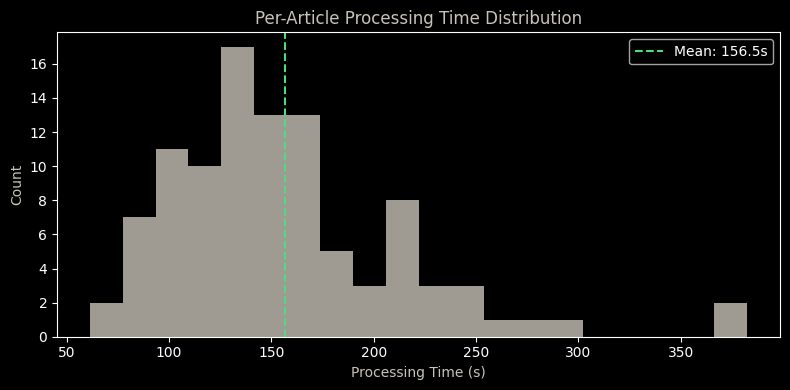

In [560]:
if "processing_time" in df.columns:
    print(f"Processing time statistics (seconds):")
    print(df["processing_time"].describe().round(2))

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.hist(df["processing_time"].dropna(), bins=20, color=COLORS["accent"], alpha=0.8)
    ax.axvline(df["processing_time"].mean(), color=COLORS["REAL"], linestyle='--',
               label=f'Mean: {df["processing_time"].mean():.1f}s')
    ax.set_xlabel("Processing Time (s)", color=COLORS["accent"])
    ax.set_ylabel("Count", color=COLORS["accent"])
    ax.set_title("Per-Article Processing Time Distribution", color=COLORS["accent"])
    ax.legend()
    plt.tight_layout()
    plt.savefig("results/processing_time.png", dpi=150, bbox_inches="tight")
    plt.show()

## 11. Limitations & Discussion

### What works well
- **Bias and credibility signals** are effective differentiators: fake articles tend to have higher bias scores and lower credibility scores.
- **Parallel execution** keeps wall-clock time reasonable even with 6 agents.
- **Devil's Advocate** helps in borderline cases (confidence < 0.6).

### Limitations
1. **Knowledge cutoff**: qwen2.5:7b has a training cutoff; it cannot fact-check events after that date.
2. **Article truncation**: Long articles are truncated to 3000 chars, which may miss key information buried later.
3. **Model hallucination**: Fact checker may confidently assess claims it cannot truly verify.
4. **Dataset bias**: The WELFake/ISOT dataset (2016–2017) primarily covers US political news; results may not generalize to other domains.
5. **JSON fragility**: Despite robust parsing, occasional complete parse failures fall back to defaults, potentially skewing results.
6. **No adversarial testing**: The pipeline has not been tested against sophisticated disinformation (e.g., articles that are factually accurate but strategically misleading).

### Future improvements
- Add a retrieval-augmented fact-checking step (RAG over a news database).
- Fine-tune a smaller classifier on extracted agent features (bias_score, credibility_score, n_contradicted) as a post-processing step.
- Add web search grounding for the fact checker agent.